In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/raw/sram_fault_dataset.csv")

In [3]:
target_columns = ["snm_hold_v", "snm_read_v"]

for target in target_columns:
    print(f"\n{target}")
    print(df[target].describe())

    print("Zero values:", (df[target] == 0).sum())


snm_hold_v
count    450.000000
mean       0.364477
std        0.172701
min        0.000000
25%        0.369700
50%        0.422300
75%        0.470100
max        0.544000
Name: snm_hold_v, dtype: float64
Zero values: 76

snm_read_v
count    450.000000
mean       0.174562
std        0.116977
min        0.000000
25%        0.000000
50%        0.226600
75%        0.263700
max        0.363500
Name: snm_read_v, dtype: float64
Zero values: 131


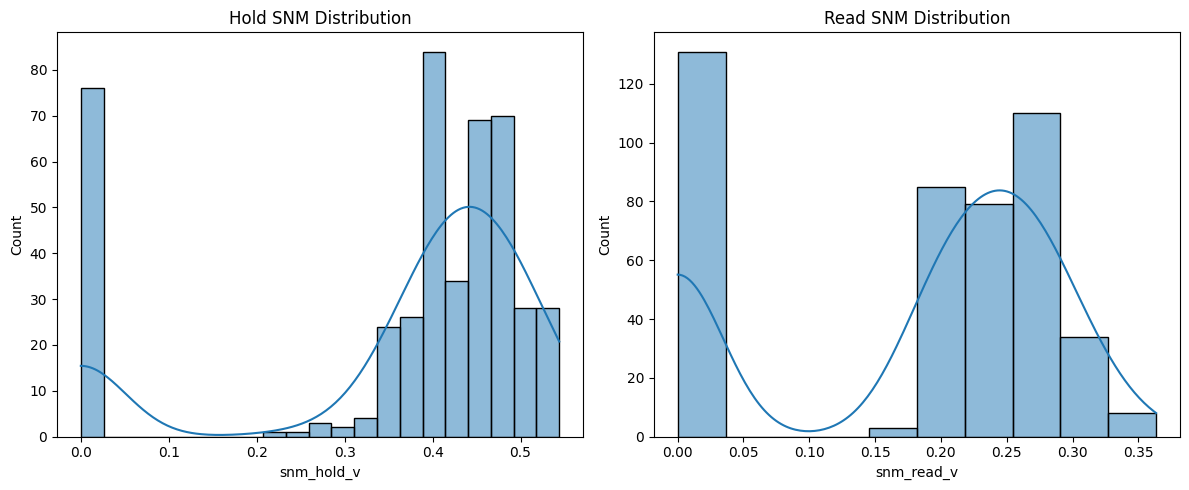

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df["snm_hold_v"], kde=True, ax=axes[0])
axes[0].set_title("Hold SNM Distribution")

sns.histplot(df["snm_read_v"], kde=True, ax=axes[1])
axes[1].set_title("Read SNM Distribution")

plt.tight_layout()
plt.show()

In [5]:
# Features available before SNM prediction
feature_columns = [
    "pvt_type",
    "vdd_v",
    "temperature_c",
    "i_ddq_uA",
    "i_write_peak_mA",
    "dv_bl_strobe_mV",
    "v_bump_mV"
]

# Predict Hold SNM
X_hold = df[feature_columns].copy()
y_hold = df["snm_hold_v"].copy()

# Predict Read SNM
X_read = df[feature_columns].copy()
y_read = df["snm_read_v"].copy()

# Group identifiers for validation
groups = df["corner_id"].copy()

print("Hold regression:", X_hold.shape, y_hold.shape)
print("Read regression:", X_read.shape, y_read.shape)
print("Number of PVT corners:", groups.nunique())

Hold regression: (450, 7) (450,)
Read regression: (450, 7) (450,)
Number of PVT corners: 15


In [6]:
print("Missing values in Hold features:",
      X_hold.isnull().sum().sum())

print("Missing values in Read features:",
      X_read.isnull().sum().sum())

print("\nHold SNM range:")
print(y_hold.min(), "to", y_hold.max())

print("\nRead SNM range:")
print(y_read.min(), "to", y_read.max())

print("\nUnique PVT corners:", groups.unique())

Missing values in Hold features: 0
Missing values in Read features: 0

Hold SNM range:
0.0 to 0.544

Read SNM range:
0.0 to 0.3635

Unique PVT corners: ['C_M40C_0P9V' 'C_0C_0P9V' 'C_27C_0P9V' 'C_75C_0P9V' 'C_125C_0P9V'
 'C_M40C_1P0V' 'C_0C_1P0V' 'C_27C_1P0V' 'C_75C_1P0V' 'C_125C_1P0V'
 'C_M40C_1P1V' 'C_0C_1P1V' 'C_27C_1P1V' 'C_75C_1P1V' 'C_125C_1P1V']


In [7]:
print("Missing values in Hold features:",
      X_hold.isnull().sum().sum())

print("Missing values in Read features:",
      X_read.isnull().sum().sum())

print("\nHold SNM range:")
print(y_hold.min(), "to", y_hold.max())

print("\nRead SNM range:")
print(y_read.min(), "to", y_read.max())

print("\nUnique PVT corners:", groups.unique())

Missing values in Hold features: 0
Missing values in Read features: 0

Hold SNM range:
0.0 to 0.544

Read SNM range:
0.0 to 0.3635

Unique PVT corners: ['C_M40C_0P9V' 'C_0C_0P9V' 'C_27C_0P9V' 'C_75C_0P9V' 'C_125C_0P9V'
 'C_M40C_1P0V' 'C_0C_1P0V' 'C_27C_1P0V' 'C_75C_1P0V' 'C_125C_1P0V'
 'C_M40C_1P1V' 'C_0C_1P1V' 'C_27C_1P1V' 'C_75C_1P1V' 'C_125C_1P1V']


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.model_selection import GroupKFold, cross_validate

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Identify numerical and categorical columns
categorical_features = ["pvt_type"]

numerical_features = [
    col for col in feature_columns
    if col not in categorical_features
]

# Preprocessing for numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [9]:
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=8,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

print("Models ready:", list(models.keys()))

Models ready: ['Linear Regression', 'Random Forest']


In [10]:
cv = GroupKFold(n_splits=5)

targets = {
    "Hold SNM": y_hold,
    "Read SNM": y_read
}

results = []

for target_name, target_values in targets.items():

    X_current = X_hold if target_name == "Hold SNM" else X_read

    for model_name, model in models.items():

        pipeline = Pipeline(steps=[
            ("preprocessor", preprocessor),
            ("regressor", model)
        ])

        scores = cross_validate(
            pipeline,
            X_current,
            target_values,
            groups=groups,
            cv=cv,
            scoring={
                "mae": "neg_mean_absolute_error",
                "mse": "neg_mean_squared_error",
                "r2": "r2"
            },
            n_jobs=-1
        )

        mae = -scores["test_mae"].mean()
        rmse = np.sqrt(-scores["test_mse"].mean())
        r2 = scores["test_r2"].mean()

        results.append({
            "Target": target_name,
            "Model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

results_df = pd.DataFrame(results)

display(results_df.round(5))

,Target,Model,MAE,RMSE,R2
0,Hold SNM,Linear Regression,0.03081,0.04630,0.92662
1,Hold SNM,Random Forest,0.03114,0.04256,0.93720
2,Read SNM,Linear Regression,0.06076,0.08153,0.47977
3,Read SNM,Random Forest,0.06899,0.10535,0.15072


In [11]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Compare original features against features without voltage bump
feature_sets = {
    "With v_bump": feature_columns,
    "Without v_bump": [
        col for col in feature_columns
        if col != "v_bump_mV"
    ]
}

ablation_results = []

for target_name, target_values in targets.items():

    for feature_set_name, selected_features in feature_sets.items():

        X_current = df[selected_features].copy()

        numeric_cols = [
            col for col in selected_features
            if col != "pvt_type"
        ]

        categorical_cols = ["pvt_type"]

        preprocessing = ColumnTransformer([
            ("num", StandardScaler(), numeric_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore"),
             categorical_cols)
        ])

        for model_name, model in models.items():

            pipeline = Pipeline([
                ("preprocessor", preprocessing),
                ("regressor", clone(model))
            ])

            scores = cross_validate(
                pipeline,
                X_current,
                target_values,
                groups=groups,
                cv=cv,
                scoring={
                    "mae": "neg_mean_absolute_error",
                    "mse": "neg_mean_squared_error",
                    "r2": "r2"
                },
                n_jobs=-1
            )

            ablation_results.append({
                "Target": target_name,
                "Features": feature_set_name,
                "Model": model_name,
                "MAE": -scores["test_mae"].mean(),
                "RMSE": np.sqrt(-scores["test_mse"].mean()),
                "R2": scores["test_r2"].mean()
            })

ablation_df = pd.DataFrame(ablation_results)

display(ablation_df.round(5))

,Target,Features,Model,MAE,RMSE,R2
0,Hold SNM,With v_bump,Linear Regression,0.03081,0.04630,0.92662
1,Hold SNM,With v_bump,Random Forest,0.03114,0.04256,0.93720
2,Hold SNM,Without v_bump,Linear Regression,0.05627,0.07243,0.82150
3,Hold SNM,Without v_bump,Random Forest,0.02863,0.04117,0.94111
4,Read SNM,With v_bump,Linear Regression,0.06076,0.08153,0.47977
5,Read SNM,With v_bump,Random Forest,0.06899,0.10535,0.15072
6,Read SNM,Without v_bump,Linear Regression,0.06594,0.08582,0.42595
7,Read SNM,Without v_bump,Random Forest,0.07041,0.10633,0.13758
